# Ultra long-range modulations of the electronic structure
A charge density wave, a superlattice defined by a gate or a magnetic texture can repeat only every
tens or hundreds of unit cells, while the atoms stay periodic. The smallest cell that holds the
modulation is a supercell of $N$ unit cells, the ultracell. Without the modulation, its eigenstates
at a momentum $\mathbf k_S$ are the Bloch states of the unit cell at the $N$ momenta that fold onto
$\mathbf k_S$. `h.get_ultracell(hs)` writes the modulated supercell `hs` in these states: the bands
of the unit cell on the diagonal, and the modulation coupling momenta that differ by one of its
wavevectors. With every state kept it is the supercell exactly. With `emax` it keeps only the states
up to an energy, which pays off when the unit cell has many orbitals.
### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry, potentials

### Unfolded spectral function under a slow potential
We take graphene and a potential $V_0\cos(2\pi x_1/n)$, with $x_1$ the coordinate along
$\mathbf a_1$ in units of the lattice vector, one period over $n=20$ cells and $V_0=0.3t$.
`u.get_kdos_bands()` gives the unfolded spectral function along the k-path of graphene, per unit
cell, which is what ARPES measures on a superlattice.

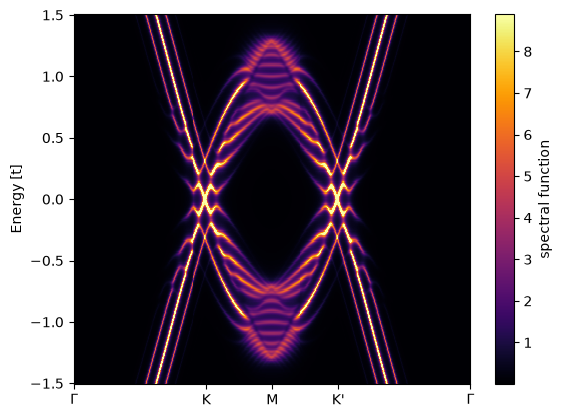

In [2]:
g = geometry.honeycomb_lattice() # unit cell of graphene
h = g.get_hamiltonian() # first-neighbor hopping, t=1
n = 20 # period of the modulation, in unit cells along a1
hs = h.get_supercell([n,1]) # the ultracell, written as a supercell
b1 = np.linalg.inv(np.array([g.a1,g.a2,g.a3]).T)[0] # b1.r is the coordinate along a1
V0 = 0.3 # amplitude of the potential, in units of t
hs.add_onsite(lambda r: V0*np.cos(2*np.pi*b1.dot(r)/n)) # one period over n cells
u = h.get_ultracell(hs) # hs solved in the Bloch states of graphene
(k,e,a) = u.get_kdos_bands(energies=np.linspace(-1.5,1.5,301),nk=400,delta=0.02,write=False)

nk, ne = len(np.unique(k)), len(np.unique(e)) # k is the outer index
(k,e,a) = [x.reshape(nk,ne) for x in (k,e,a)]
plt.pcolormesh(k,e,a,cmap="inferno",shading="auto",vmax=np.percentile(a,99))
plt.colorbar(label="spectral function")
plt.xticks([0,1/3,1/2,2/3,1],["$\\Gamma$","K","M","K'","$\\Gamma$"])
plt.ylabel("Energy [t]")
plt.show()

Each band keeps most of its weight, with weaker replicas shifted by the wavevector
$\mathbf Q=\mathbf b_1/n$ of the potential. Near M the band of graphene, at $\omega=\pm t$, is a
saddle point and changes slowly with momentum, so the potential, and not the kinetic energy, sets the levels:
its weight spreads over $t\pm V_0$, into a ladder of discrete levels.
Near K and K' the Dirac cone and its replicas cross.

### Local density of states over a modulation in two dimensions
A potential with threefold symmetry and a period of $n=30$ cells along $\mathbf a_1$ and
$\mathbf a_2$, on spinless graphene. Locally, the electrons see graphene with its Dirac point
shifted to $V(\mathbf r)$, so the local density of states at zero energy, what STM measures,
grows with $|V(\mathbf r)|$.

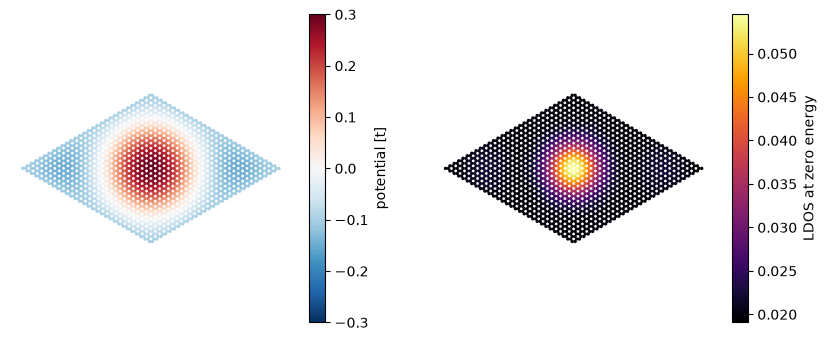

LDOS where V>0.25: 0.04795501070851358 , V<-0.13: 0.021687481695989556 , |V|<0.02: 0.01995371424899448


In [3]:
h = g.get_hamiltonian(has_spin=False) # spinless graphene
n = 30 # period of the modulation, in unit cells along a1 and a2
hs = h.get_supercell([n,n]) # the ultracell, written as a supercell
B = np.linalg.inv(np.array([g.a1,g.a2,g.a3]).T) # B@r are the coordinates along a1, a2
V0 = 0.1 # amplitude of each plane wave, in units of t
def V(r): # a potential with the period of the ultracell and threefold symmetry
    x1,x2 = 2*np.pi*(B@r)[0:2]/n
    return V0*(np.cos(x1) + np.cos(x2) + np.cos(x1-x2))
hs.add_onsite(V) # add it to the ultracell
u = h.get_ultracell(hs) # hs solved in the Bloch states of graphene
(x,y,d) = u.get_ldos(e=0.0,delta=0.03,nk=2,write=False) # LDOS at the Dirac energy
v = np.array([V(r) for r in hs.geometry.r]) # the potential on each site

fig,axs = plt.subplots(1,2,figsize=(10,4))
s = axs[0].scatter(x,y,c=v,s=2,cmap="RdBu_r",vmin=-0.3,vmax=0.3)
plt.colorbar(s,ax=axs[0],label="potential [t]")
s = axs[1].scatter(x,y,c=d,s=2,cmap="inferno")
plt.colorbar(s,ax=axs[1],label="LDOS at zero energy")
for ax in axs: ax.set_aspect("equal") ; ax.set_axis_off()
plt.show()
print("LDOS where V>0.25:",d[v>0.25].mean(),", V<-0.13:",d[v<-0.13].mean(),
      ", |V|<0.02:",d[np.abs(v)<0.02].mean())

The LDOS at zero energy is largest on the maxima of the potential, where $V=0.3t$, about
twice the value on the minima, where $V=-0.15t$, and lowest on the lines where $V$ vanishes, where
only the broadening gives weight.

### Keeping only the low-energy states
A $4\times4$ cell of the triangular lattice with a moire potential has 16 orbitals. Over $9\times9$
of these cells the supercell has 1296 states, and the low-energy physics lives in the lowest two
bands. With `emax` we keep only the states of the unit cell up to that energy, and compare the levels
below $-1.9t$ with the full basis.

In [4]:
g = geometry.triangular_lattice().get_supercell(4) # a 4x4 cell of the triangular lattice
h = g.get_hamiltonian(has_spin=False) # 16 orbitals per cell
h.add_onsite(potentials.commensurate_potential(g,n=3,minmax=[0,2])) # moire potential, periodic on the cell
n = 9 # period of the slow modulation, in moire cells
hs = h.get_supercell([n,n]) # the ultracell, 81 moire cells
B = np.linalg.inv(np.array([g.a1,g.a2,g.a3]).T) # B@r are the coordinates along a1, a2
def V(r): # slow modulation, 0.1 t at most
    x1,x2 = 2*np.pi*(B@r)[0:2]/n
    return 0.05*(np.cos(x1) + np.cos(x2))
hs.add_onsite(V)
kS = [0.13,0.29,0.] # a Bloch momentum of the ultracell
e0 = np.linalg.eigvalsh(h.get_ultracell(hs).get_hk_gen()(kS)) # every state, exact
low = e0[e0<-1.9] # the levels we care about
print("every state:",len(e0),"rows,",len(low),"levels below -1.9")
for emax in [-1.8,-1.7,-1.5]:
    u = h.get_ultracell(hs,emax=emax) # keep the states up to emax
    m = u.get_hk_gen()(kS) # the ultracell matrix
    e = np.linalg.eigvalsh(m)
    print("emax",emax,":",m.shape[0],"rows, largest error",np.max(np.abs(e[0:len(low)]-low)))

every state: 1296 rows, 89 levels below -1.9
emax -1.8 : 131 rows, largest error 0.005321469648618127
emax -1.7 : 150 rows, largest error 0.0002864299304405904
emax -1.5 : 168 rows, largest error 0.0002036054823510991


With `emax=-1.7` the matrix has about a tenth of the rows, and the levels below $-1.9t$ agree
with the full basis to a few $10^{-4}t$. A state at a distance $\Delta E$ in energy enters with a
weight of order $(V/\Delta E)^2$, so we keep a margin above the energies we look at of about twice
the modulation. The cut is in energy and not in band index, since the two lowest bands of the moire
cell overlap in energy.

### Mean field over the modulation
`u.get_mean_field_hamiltonian()` runs the self-consistent mean field of the supercell, with the keywords
of `h.get_mean_field_hamiltonian()`, and computes the density matrix of every iteration in the ultracell
states. We take a paramagnetic insulator, the honeycomb lattice with onsite energies $+1$ on A and $-1$ on
B, under an exchange field $B_0\cos(2\pi x_1/n)\sigma_z$ with $B_0=0.05t$ and $n=24$, and compare the moment
it induces without and with a Hubbard $U=1.5t$. The k-mesh has one number per direction: the ultracell is
24 cells long along $\mathbf a_1$ and one cell along $\mathbf a_2$.

enhancement of the induced moment: 1.8219862841069003


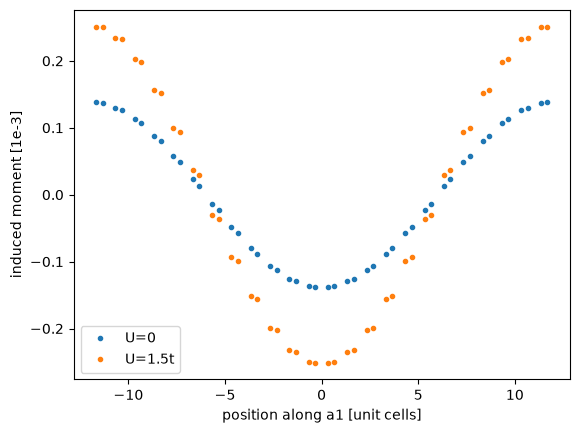

In [5]:
g = geometry.honeycomb_lattice() # unit cell of the honeycomb lattice
h = g.get_hamiltonian() # spinful, first-neighbor hopping t=1
h.add_sublattice_imbalance(1.0) # +1 on A and -1 on B, a gap of 2t
n = 24 # period of the modulation, in unit cells along a1
hs = h.get_supercell([n,1]) # the ultracell, written as a supercell
b1 = np.linalg.inv(np.array([g.a1,g.a2,g.a3]).T)[0] # b1.r is the coordinate along a1
B0 = 0.05 # amplitude of the exchange field, in units of t
hs.add_exchange(lambda r: [0.,0.,B0*np.cos(2*np.pi*b1.dot(r)/n)]) # along z
u = h.get_ultracell(hs) # hs solved in the Bloch states of the unit cell
nk = [2,12] # k-mesh of the ultracell
m0 = u.get_vev(operator="sz",nk=nk) # induced moment without interaction
u2 = u.get_mean_field_hamiltonian(U=1.5,filling=0.5,mf="ferroZ",nk=nk,verbose=0,write=False) # Hubbard U
m = u2.get_vev(operator="sz",nk=nk) # induced moment with the Hubbard U
x = np.array([b1.dot(r) for r in u2.hs.geometry.r]) # coordinate along a1
print("enhancement of the induced moment:",np.max(np.abs(m))/np.max(np.abs(m0)))

o = np.argsort(x)
plt.plot(x[o],1e3*m0[o],"o",ms=3,label="U=0")
plt.plot(x[o],1e3*m[o],"o",ms=3,label="U=1.5t")
plt.xlabel("position along a1 [unit cells]") ; plt.ylabel("induced moment [1e-3]")
plt.legend()
plt.show()

The moment follows the field cell by cell, with the opposite sign, since `add_exchange` adds
$\mathbf B\cdot\boldsymbol\sigma$. The Hubbard $U$ keeps the insulator paramagnetic and enhances its
spin response, by a factor 1.82, which at linear order is the RPA enhancement of the spin response at the
wavevector of the field. The factor is the same on a mesh twice finer along $\mathbf a_2$.